# 05 · A/B test `AdsConfig_iOS`

**Question.** Does a variant of the ad configuration change retention, ad exposure or ad revenue?
**Answer.** No difference in D1 or D7 can be detected: the test has about 1,000 players per variant and could only see a D1 change of about 6 points. Variant B shows fewer interstitials on the first day (-20%), a lead to confirm. A conclusive test on D1 needs about 9,400 players per variant.
**Method.** Sample ratio and balance checks, retention from the join day with Newcombe intervals, ad metrics per player with bootstrap intervals (3,000 resamples), power analysis (`game_events.experiment`, `game_events.stats`). The content of each variant is not documented: results describe what changed in the data, not what the variant was.

In [1]:
import matplotlib.pyplot as plt

from game_events import config, experiment, stats
from game_events.data import connect_events
from game_events.queries import build_base_tables, build_experiment_players

con, readable, unreadable = connect_events()
build_base_tables(con)
build_experiment_players(con)
print(f"{len(readable)} readable files, {len(unreadable)} skipped")

67 readable files, 1 skipped


## 1. Population

In [2]:
con.sql("""
    SELECT variant, COUNT(*) AS players, MIN(join_day) AS first_join, MAX(join_day) AS last_join,
           COUNT(*) FILTER (WHERE joins > 1)         AS joined_twice,
           COUNT(*) FILTER (WHERE variants_seen > 1) AS saw_two_variants
    FROM exp_players GROUP BY 1 ORDER BY 1
""").show(max_width=200)

┌─────────────────┬─────────┬────────────┬────────────┬──────────────┬──────────────────┐
│     variant     │ players │ first_join │ last_join  │ joined_twice │ saw_two_variants │
│     varchar     │  int64  │    date    │    date    │    int64     │      int64       │
├─────────────────┼─────────┼────────────┼────────────┼──────────────┼──────────────────┤
│ Control-Variant │    1105 │ 2025-03-07 │ 2025-04-10 │           19 │                0 │
│ Variant-A       │    1093 │ 2025-03-07 │ 2025-04-10 │           15 │                0 │
│ Variant-B       │    1131 │ 2025-03-07 │ 2025-04-10 │           16 │                0 │
└─────────────────┴─────────┴────────────┴────────────┴──────────────┴──────────────────┘



No player saw two variants: the groups are not contaminated.

## 2. Is the split random and balanced?

In [3]:
sizes = con.execute("SELECT variant, COUNT(*) AS n FROM exp_players GROUP BY 1 ORDER BY 1").df()
print(sizes.to_string(index=False))
print(f"Sample ratio mismatch, p-value: {stats.srm_pvalue(sizes['n']):.2f}")

con.execute("""
    CREATE OR REPLACE TABLE exp_events AS
    SELECT e.user_id, e.event_name, e.ts, e.client_platform, e.country_code,
           e.user_properties_custom['appVersion'] AS app_version
    FROM events e JOIN exp_players p USING (user_id)
""")
con.sql("""
    SELECT p.variant,
           COUNT(DISTINCT p.user_id)                                                   AS players,
           COUNT(DISTINCT p.user_id) FILTER (WHERE e.client_platform = 'IPhonePlayer') AS with_iphone_events,
           COUNT(DISTINCT p.user_id) FILTER (WHERE e.country_code = 'US')              AS with_us_events
    FROM exp_players p JOIN exp_events e USING (user_id)
    GROUP BY 1 ORDER BY 1
""").show(max_width=200)

        variant    n
Control-Variant 1105
      Variant-A 1093
      Variant-B 1131
Sample ratio mismatch, p-value: 0.71


┌─────────────────┬─────────┬────────────────────┬────────────────┐
│     variant     │ players │ with_iphone_events │ with_us_events │
│     varchar     │  int64  │       int64        │     int64      │
├─────────────────┼─────────┼────────────────────┼────────────────┤
│ Control-Variant │    1105 │               1105 │           1105 │
│ Variant-A       │    1093 │               1093 │           1093 │
│ Variant-B       │    1131 │               1131 │           1131 │
└─────────────────┴─────────┴────────────────────┴────────────────┘



In [4]:
con.sql("""
    WITH first_event AS (SELECT user_id, MIN(ts) AS t FROM exp_events GROUP BY 1)
    SELECT p.variant,
           ROUND(MEDIAN(epoch(p.join_ts - f.t) / 3600), 2)                                    AS median_hours_after_first_event,
           ROUND(100.0 * COUNT(*) FILTER (WHERE epoch(p.join_ts - f.t) / 3600 > 24) / COUNT(*), 1) AS pct_joined_after_24h
    FROM exp_players p JOIN first_event f USING (user_id)
    GROUP BY 1 ORDER BY 1
""").show(max_width=200)

con.sql("""
    SELECT p.variant, e.app_version, COUNT(DISTINCT p.user_id) AS players
    FROM exp_players p
    JOIN exp_events e ON e.user_id = p.user_id AND CAST(e.ts AS DATE) = p.join_day
    WHERE e.app_version IS NOT NULL
    GROUP BY 1, 2 ORDER BY 1, 3 DESC
""").show(max_rows=12, max_width=200)

┌─────────────────┬────────────────────────────────┬──────────────────────┐
│     variant     │ median_hours_after_first_event │ pct_joined_after_24h │
│     varchar     │             double             │        double        │
├─────────────────┼────────────────────────────────┼──────────────────────┤
│ Control-Variant │                            0.0 │                  0.1 │
│ Variant-A       │                            0.0 │                  0.0 │
│ Variant-B       │                            0.0 │                  0.1 │
└─────────────────┴────────────────────────────────┴──────────────────────┘

┌─────────────────┬─────────────┬─────────┐
│     variant     │ app_version │ players │
│     varchar     │   varchar   │  int64  │
├─────────────────┼─────────────┼─────────┤
│ Control-Variant │ 0.21.21     │     641 │
│ Control-Variant │ 0.21.23     │     468 │
│ Variant-A       │ 0.21.21     │     619 │
│ Variant-A       │ 0.21.23     │     469 │
│ Variant-B       │ 0.21.21     │     6

Balanced: no sample ratio mismatch, players join at their first moment in the game, and the app versions are spread alike. Every player has iPhone and US events in all three groups, so neither platform nor country explains a difference.

## 3. Retention from the join day

Difference to control in points, 95% Newcombe interval. Days falling on the data gap are left out.

In [5]:
experiment.experiment_retention(con, days=(1, 7))

,day_n,variant,players,pct,diff_pts,ci_low,ci_high
0,1,Control-Variant,1022,38.3,NaN,NaN,NaN
1,1,Variant-A,1011,38.3,0.0,-4.2,4.2
2,1,Variant-B,1028,39.7,1.4,-2.8,5.6
3,7,Control-Variant,829,6.5,NaN,NaN,NaN
4,7,Variant-A,794,7.3,0.8,-1.7,3.3
5,7,Variant-B,822,7.1,0.5,-1.9,3.0


## 4. Ad exposure and revenue per player

Join day, then the first 7 days (players who joined at least 7 days before the last full day). Revenue is also shown capped at 1 USD per impression.

In [6]:
METRICS = ["interstitials", "rewarded", "revenue_usd", "revenue_capped_usd"]
day0 = experiment.ads_per_player(con, 0, config.LAST_FULL_DAY)
res_day0 = experiment.compare_to_control(day0, METRICS)
res_day0

,metric,variant,players,mean,diff,pct_change,ci_low,ci_high
0,interstitials,Control-Variant,1077,7.516,NaN,NaN,NaN,NaN
1,interstitials,Variant-A,1056,7.940,0.424,5.6,-0.658,1.521
2,interstitials,Variant-B,1102,6.046,-1.470,-19.6,-2.398,-0.573
3,rewarded,Control-Variant,1077,4.373,NaN,NaN,NaN,NaN
4,rewarded,Variant-A,1056,4.003,-0.370,-8.5,-1.144,0.384
5,rewarded,Variant-B,1102,4.384,0.011,0.2,-0.857,0.942
6,revenue_usd,Control-Variant,1077,0.952,NaN,NaN,NaN,NaN
7,revenue_usd,Variant-A,1056,0.943,-0.009,-0.9,-0.237,0.219
8,revenue_usd,Variant-B,1102,0.874,-0.078,-8.2,-0.300,0.160
9,revenue_capped_usd,Control-Variant,1077,0.942,NaN,NaN,NaN,NaN


In [7]:
week = experiment.ads_per_player(con, 6, "2025-04-03")
experiment.compare_to_control(week, METRICS)

,metric,variant,players,mean,diff,pct_change,ci_low,ci_high
0,interstitials,Control-Variant,876,14.362,NaN,NaN,NaN,NaN
1,interstitials,Variant-A,840,14.537,0.175,1.2,-2.468,2.733
2,interstitials,Variant-B,873,13.042,-1.319,-9.2,-3.902,1.303
3,rewarded,Control-Variant,876,7.927,NaN,NaN,NaN,NaN
4,rewarded,Variant-A,840,8.436,0.509,6.4,-2.415,4.249
5,rewarded,Variant-B,873,9.283,1.356,17.1,-1.068,3.649
6,revenue_usd,Control-Variant,876,1.286,NaN,NaN,NaN,NaN
7,revenue_usd,Variant-A,840,1.380,0.095,7.4,-0.222,0.402
8,revenue_usd,Variant-B,873,1.257,-0.028,-2.2,-0.328,0.290
9,revenue_capped_usd,Control-Variant,876,1.249,NaN,NaN,NaN,NaN


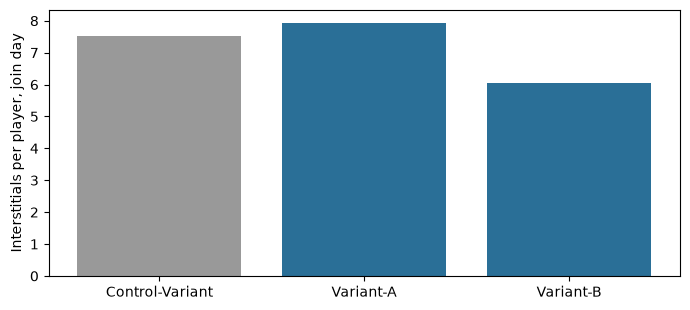

In [8]:
d = res_day0[res_day0["metric"] == "interstitials"]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(d["variant"], d["mean"], color=["#999999", "#2a6f97", "#2a6f97"])
ax.set_ylabel("Interstitials per player, join day")
plt.tight_layout()
plt.show()

16 comparisons (4 metrics, 2 variants, 2 windows): one interval can exclude 0 by chance, so a single borderline result is a lead, not a conclusion.

## 5. Purchases

In [9]:
con.sql("""
    SELECT event_name, COUNT(*) AS events, COUNT(DISTINCT user_id) AS players
    FROM exp_events
    WHERE event_name IN ('purchaseCompleted', 'inAppPurchase', 'starterPack', 'superStarterPack', 'noAds24Hours', 'noAds')
    GROUP BY 1 ORDER BY 2 DESC
""").show()

┌──────────────────┬────────┬─────────┐
│    event_name    │ events │ players │
│     varchar      │ int64  │  int64  │
├──────────────────┼────────┼─────────┤
│ starterPack      │     94 │      90 │
│ superStarterPack │     32 │      31 │
│ noAds            │      7 │       7 │
│ noAds24Hours     │      2 │       2 │
└──────────────────┴────────┴─────────┘



`purchaseCompleted` is tracked on Android only, so purchases are not an outcome of this iPhone test. Product-named events exist but are not documented.

## 6. Sample size for a conclusive test

Baseline: control D1 of 38.3%. Two-sided test, 80% power.

In [10]:
baseline = 0.383
print(f"+2 points, one variant vs control:  {stats.sample_size_per_variant(baseline, 0.02):,} players per variant")
print(f"+2 points, two variants (Bonferroni): {stats.sample_size_per_variant(baseline, 0.02, alpha=0.025):,} players per variant")
print(f"Smallest detectable change with 1,000 players per variant: "
      f"{100 * stats.minimum_detectable_effect(baseline, 1000):.1f} points")

+2 points, one variant vs control:  9,361 players per variant
+2 points, two variants (Bonferroni): 11,336 players per variant
Smallest detectable change with 1,000 players per variant: 6.2 points


## Findings

- **The experiment.** `AdsConfig_iOS`, three variants: `Control-Variant` (1,105 players), `Variant-A` (1,093) and `Variant-B` (1,131), from 2025-03-07 to 2025-04-10. All are iPhone players, joined at their very first moment in the game, and all have activity in the US. The split looks random: the sample ratio check gives p = 0.71 (no sign of a biased assignment), the share of app versions is similar in the three groups, and no player saw two variants.
- **Retention: no difference detected.** D1 is 38.3% (control), 38.3% (A) and 39.7% (B); the differences to control are 0.0 (interval -4.2 to +4.2) and +1.4 points (-2.8 to +5.6). D7 is 6.5%, 7.3% and 7.1%; differences +0.8 (-1.7 to +3.3) and +0.5 (-1.9 to +3.0). With about 1,000 players per variant, the smallest D1 difference this test could detect with 80% power is about 6 points (section 6): smaller effects would usually go unseen.
- **Ad exposure: Variant B shows fewer interstitials on the first day.** 6.0 interstitials per player against 7.5 in control (-19.6%, interval -2.4 to -0.6 per player: it excludes 0). Variant A is close to control (+5.6%, interval -0.6 to +1.6). Rewarded videos and estimated ad revenue show no detectable difference on the first day, and over the first 7 days no interval excludes 0 (B: -1.3 interstitials per player, interval -3.8 to +1.1).
- **Reading.** Variant B appears to reduce early interstitial exposure without a visible effect on D1, D7 or estimated revenue, but the test cannot rule out moderate effects on those. What each variant changed is not documented. Given the number of comparisons (4 metrics, 2 variants, 2 windows), the interstitial result is a lead to confirm, not a proof.
- **A conclusive test needs about ten times more players.** Detecting a 2-point change of D1 with 80% power needs 9,361 players per variant, or 11,336 when two variants are compared with the control (Bonferroni).
- **Purchases are not measurable here.** `purchaseCompleted` and `inAppPurchase` only occur for Android players; the iPhone players of this test have none of them.

**Limits.**
- The content of the variants is unknown.
- About 1,100 players per variant: small effects cannot be seen.
- iPhone players in the US only: the result does not transfer to Android or other countries.
- Purchases are not measurable for this population.